# Exercise 2.3 Solutions | Bivariate Relationships by Category

Has the relationship between income and voting changed over time?

In [1]:
# Imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Data path
file_path = 'https://econ-0150.tayweid.io/data/'

## Load the Data

In [2]:
# Elections data (dem_share and total_votes for each year)
elections = pd.read_csv(file_path + 'Elections_By_County.csv')
elections.head()

,county_fips,dem_share_2000,dem_share_2004,dem_share_2008,dem_share_2012,dem_share_2016,dem_share_2020,dem_share_2024,total_votes_2000,total_votes_2004,total_votes_2008,total_votes_2012,total_votes_2016,total_votes_2020,total_votes_2024
0,1001,0.291822,0.238448,0.259321,0.268006,0.246225,0.274423,0.266411,17208.0,20081.0,23641.0,23932.0,24973.0,27770.0,28281.0
1,1003,0.255099,0.227490,0.240351,0.218190,0.202078,0.227317,0.206524,56480.0,69320.0,81413.0,85338.0,95215.0,109679.0,122249.0
2,1005,0.504473,0.450284,0.492692,0.515791,0.471768,0.461391,0.425850,10395.0,10777.0,11630.0,11509.0,10469.0,10518.0,9855.0
3,1007,0.388085,0.276286,0.268543,0.264219,0.217603,0.208811,0.176151,7101.0,7600.0,8644.0,8420.0,8819.0,9595.0,9257.0
4,1009,0.282079,0.184675,0.147296,0.125174,0.086188,0.096523,0.092231,17973.0,21504.0,24267.0,24006.0,25588.0,27588.0,28163.0


In [3]:
# Income data
income = pd.read_csv(file_path + 'Income_By_County.csv', index_col=0)
income = income[['county_fips', 'Median Household Income']].dropna()
income.columns = ['county_fips', 'income']
income.head()

,county_fips,income
0,0,77719.0
1,1000,62248.0
2,1001,68857.0
3,1003,74248.0
4,1005,45298.0


## Merging Datasets

To ask questions that require both income and elections data, we need to combine them using `pd.merge()`.

In [4]:
# Merge on county_fips
data = pd.merge(income, elections, on='county_fips')
data.head()

,county_fips,income,dem_share_2000,dem_share_2004,dem_share_2008,dem_share_2012,dem_share_2016,dem_share_2020,dem_share_2024,total_votes_2000,total_votes_2004,total_votes_2008,total_votes_2012,total_votes_2016,total_votes_2020,total_votes_2024
0,1001,68857.0,0.291822,0.238448,0.259321,0.268006,0.246225,0.274423,0.266411,17208.0,20081.0,23641.0,23932.0,24973.0,27770.0,28281.0
1,1003,74248.0,0.255099,0.227490,0.240351,0.218190,0.202078,0.227317,0.206524,56480.0,69320.0,81413.0,85338.0,95215.0,109679.0,122249.0
2,1005,45298.0,0.504473,0.450284,0.492692,0.515791,0.471768,0.461391,0.425850,10395.0,10777.0,11630.0,11509.0,10469.0,10518.0,9855.0
3,1007,56025.0,0.388085,0.276286,0.268543,0.264219,0.217603,0.208811,0.176151,7101.0,7600.0,8644.0,8420.0,8819.0,9595.0,9257.0
4,1009,64962.0,0.282079,0.184675,0.147296,0.125174,0.086188,0.096523,0.092231,17973.0,21504.0,24267.0,24006.0,25588.0,27588.0,28163.0


## Reshape: Wide Format to Long Format

Sometimes we need wide; sometimes we need long. Here we stack the 2000 and 2024 vote shares into one `dem_share` column, with a `Year` column telling them apart.

In [5]:
data_long = data.melt(
    id_vars=['county_fips', 'income'],
    value_vars=['dem_share_2000', 'dem_share_2024'],
    var_name='Year',
    value_name='dem_share'
)
data_long['Year'] = data_long['Year'].str.replace('dem_share_', '')

## Question 1: Has county-level voting changed?

Create a boxplot comparing Democratic vote share in 2000 vs 2024.

Text(0.5, 1.0, 'Democratic Vote Share by County, 2000 vs 2024')

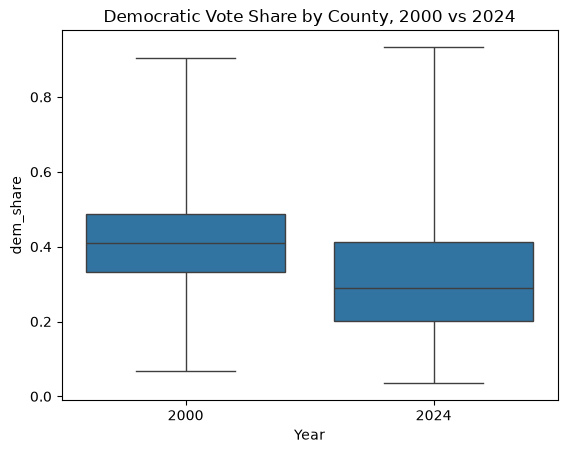

In [6]:
sns.boxplot(data=data_long, x='Year', y='dem_share', whis=(0,100))
plt.title('Democratic Vote Share by County, 2000 vs 2024')

Yes. The typical county voted noticeably less Democratic in 2024 than in 2000: the whole 2024 box sits lower (median about 0.29 vs 0.41). The 2024 distribution is also more spread out, so counties have pulled further apart.

## Question 2: Do large counties vote differently?

Create a scatter plot of county size (total_votes_2024) vs Democratic share (dem_share_2024).

Text(0.5, 1.0, 'County Size vs Democratic Share, 2024')

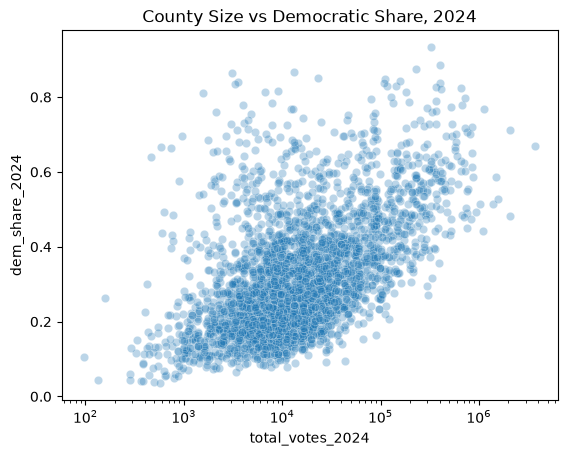

In [7]:
sns.scatterplot(data=data, x='total_votes_2024', y='dem_share_2024', alpha=0.3)
plt.xscale('log')
plt.title('County Size vs Democratic Share, 2024')

Yes. Larger counties vote more Democratic. County size is heavily right-skewed, so a log scale on the x-axis makes the positive relationship much easier to see.

## Question 3: Is this related to income?

Create a scatter plot of income vs Democratic share (dem_share_2024).

Text(0.5, 1.0, 'Median Household Income vs Democratic Share, 2024')

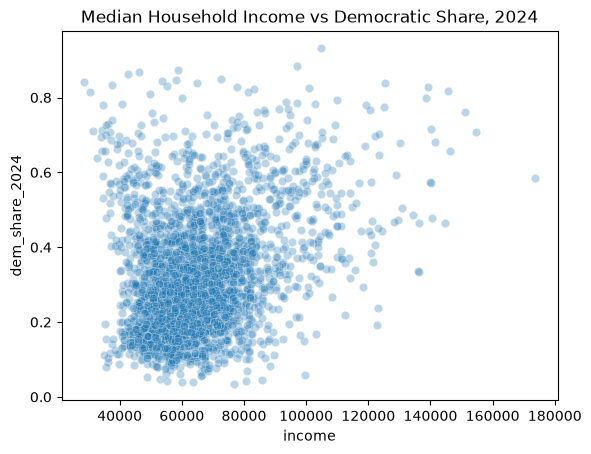

In [8]:
sns.scatterplot(data=data, x='income', y='dem_share_2024', alpha=0.3)
plt.title('Median Household Income vs Democratic Share, 2024')

In 2024, higher-income counties tend to vote more Democratic. The relationship is positive but weak, with a lot of scatter around it.

## Question 4: Has the relationship changed?

Create a scatter plot of income vs Democratic share, colored by year (2000 vs 2024).

Hint: Use `data_long` and `hue='Year'` in `sns.lmplot()`

Text(0.5, 1.0, 'Income vs Democratic Share, 2000 vs 2024')

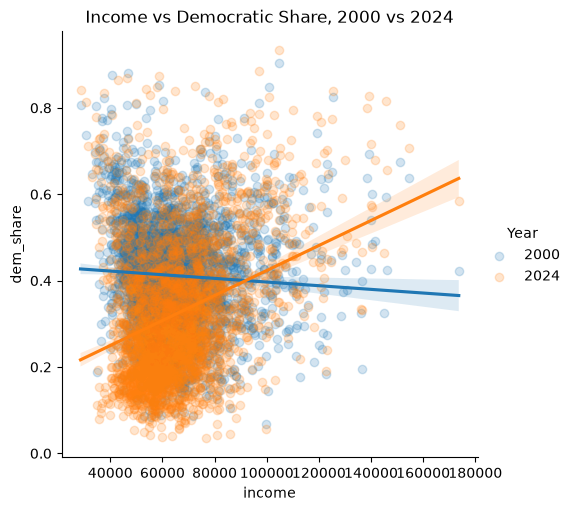

In [9]:
sns.lmplot(data=data_long, x='income', y='dem_share', hue='Year', scatter_kws={'alpha': 0.2})
plt.title('Income vs Democratic Share, 2000 vs 2024')

Yes. In 2000 there was essentially no relationship between county income and Democratic share (the line is nearly flat, slightly negative). By 2024 the line slopes clearly upward: richer counties became more Democratic relative to poorer ones. The 2024 line also sits lower overall, matching the shift in Question 1.